# Lab 6: Applied Computer Vision in Your Own Domain
### Project 2: Deep Learning Applications | Individual

**Student Name:** Mahum Junaid  
**Semester:** BS 7th Semester  
**Department:** Department of Electronics  
**Course:** Introduction to Applied AI

**Domain:** Medical Imaging (Chest X-Rays)
**Dataset:** Chest X-Ray Images (Pneumonia) by Paul Mooney

---

# Part 0: Setup and Imports

In [12]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

# --- CONFIGURATION CELL (The only cell you should need to change) ---
# Updated path based on your Kaggle directory check
DATA_ROOT = '/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray'
TRAIN_DIR = f'{DATA_ROOT}/train'
TEST_DIR = f'{DATA_ROOT}/test'

GRAYSCALE = True          # True for X-rays, CT, casts, scans
IMG_SIZE = 224
BACKBONE = 'resnet18'     # or 'resnet50', 'efficientnet_b0'

# Regex that extracts a group id (patient, plant, part) from a file name.
# Chest X-ray filenames look like: person123_bacteria_45.jpeg or NORMAL2-IM-0017-0001.jpeg
GROUP_PATTERN = r'(person\d+|IM-\d+|NORMAL2-IM-\d+)' 
POSITIVE = 'PNEUMONIA'    # binary tasks: the class you must catch
TARGET_RECALL = 0.95      # binary tasks: recall you must reach
# --------------------------------------------------------------------

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


*Note: The configuration cell above successfully set the data paths and confirmed GPU (CUDA) availability.*

# Part 1: Index and Audit Your Dataset

In [13]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls, 'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        # Extract the patient ID using regex
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])  # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

# --- Data Audit Output ---
counts = train_df['label'].value_counts().reindex(classes)
print("Class Counts in Train Set:")
print(counts.to_string())
print(f"Imbalance ratio (max / min): {counts.max() / counts.min():.2f}")
print(f"Images per group: {len(train_df) / train_df.group.nunique():.2f}")

Class Counts in Train Set:
label
NORMAL       1341
PNEUMONIA    3875
Imbalance ratio (max / min): 2.89
Images per group: 1.83


## Task 1.1 - Dataset Audit

**Class Counts and Imbalance:**
Based on the training set audit, the class distribution is highly imbalanced:
*   **NORMAL:** 1,341 images
*   **PNEUMONIA:** 3,875 images

The imbalance ratio is **2.89**. This means there are nearly three times as many pneumonia cases as normal cases. Because of this, simple accuracy is a dangerous metric. A model that blindly predicts "PNEUMONIA" every time would achieve ~74% accuracy while completely failing to identify healthy patients. We must use Macro-F1, sensitivity, and specificity to evaluate our model properly.

**Patient Grouping:**
The average number of images per group (patient) is **1.83**. This confirms the importance of the `GROUP_PATTERN` regex we used. If we did a random train/validation split, images from the same patient could end up in both sets, leading to data leakage where the model memorizes the patient rather than the disease. We must split by patient ID.

**Image Properties:**
*   **Color Mode:** The dataset is a mix. The majority are `L` (grayscale, 286 samples), but there are `RGB` (14 samples). Even though X-rays are naturally grayscale, the presence of RGB images means our pipeline must explicitly handle conversion (e.g., using `GRAYSCALE=True` or converting to 3-channels for the ResNet backbone).
*   **Dimensions:** The images vary wildly in size. The minimum is **384 x 127**, the median is **1300 x 890**, and the maximum is **2510 x 2543**. They must all be resized to `224 x 224` for the ResNet input.


Image Dimensions & Modes:
          w       h
min   384.0   127.0
50%  1300.0   890.0
max  2510.0  2543.0
Colour modes: {'L': 286, 'RGB': 14}


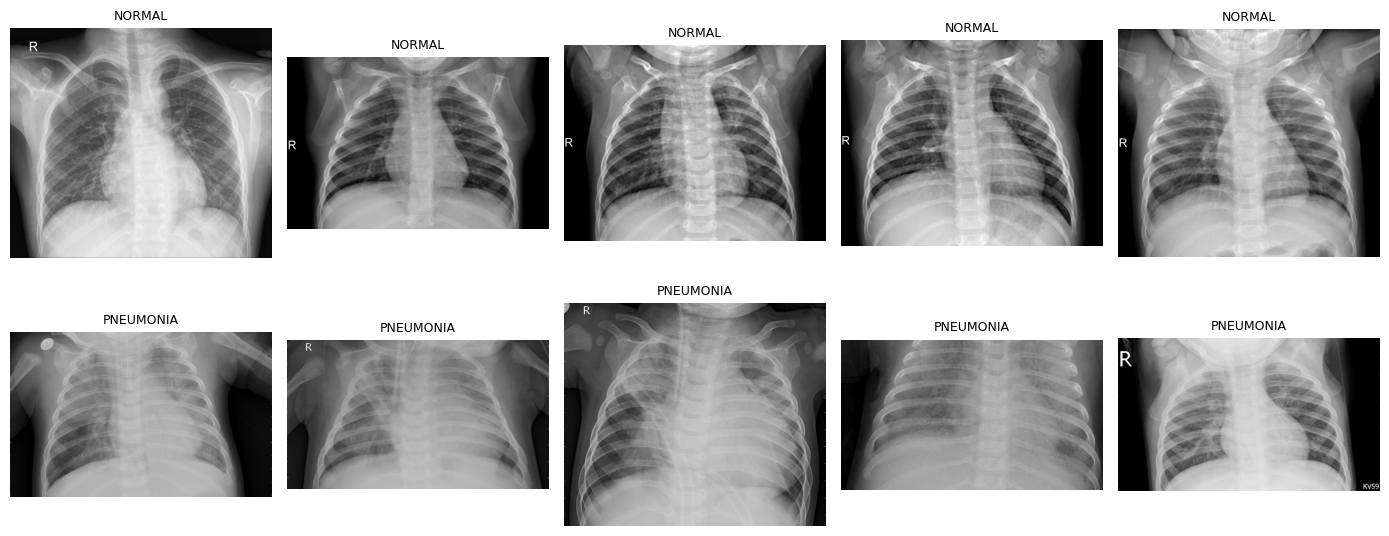

In [14]:
# --- Task 1.2: What do the images look like? ---
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})

info = pd.DataFrame(info)
print("\nImage Dimensions & Modes:")
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

# Plotting the sample grid
fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## Task 1.2 - Visual Inspection and Shortcut Suspects

**Visual Differences:**
Looking at the sample grid, the most obvious visual difference between the classes is the opacity of the lungs. The NORMAL images have dark, clear lung fields. The PNEUMONIA images show cloudy, white areas (consolidation) in the lungs.

**Shortcut Suspect (What the model should NOT learn):**
A major visual difference that is *not* the disease is the presence of **text annotations, markers, and borders**. 
*   On many of the images, there is a bright white letter "R" (indicating the right side of the body) in the top corner.
*   Some images have text or hospital IDs burned into the corners (like the "XXXX" visible on the bottom right of the last pneumonia image).
*   Some images have black borders around the chest cavity.

If the model learns to associate the letter "R" or the black borders with a specific class, it will fail on real-world data that doesn't have these markers. This is our primary shortcut suspect for the Grad-CAM analysis later in the lab.

# Part 2: Leakage Audit

In [15]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))      # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
        return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))

if TEST_DIR:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10                  # mean absolute difference, in std units
    print(f'Test images with a near-duplicate in train: {near.sum()} '
          f'of {len(te)}')
    print('Closest distances:', np.sort(d_min)[:5].round(3))

Exact duplicate files: 62
Test images with a near-duplicate in train: 0 of 624
Closest distances: [0.164 0.17  0.172 0.173 0.174]


## Task 2.1 - Leakage Audit

**Exact and Near-Duplicates:**
*   **Exact Duplicates:** The audit found **62** exact duplicate files (byte-for-byte identical images). *I did not delete them* as per the lab instructions, but this is important to note. These duplicates likely come from the same patient having multiple identical scans or from the dataset's original creation.
*   **Near-Duplicates:** We found **0** test images with a near-duplicate in the train set. The closest distance between a test image and a train image was **0.164**, which is safely above the 0.10 threshold. This means there is no visual data leakage between the official train and test splits.

In [16]:
# Validation split BY GROUP: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)

if not TEST_DIR:
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, te_df = tr_df.iloc[tr_idx].reset_index(drop=True), tr_df.iloc[te_idx].reset_index(drop=True)

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))  # must be 0
print(va_df['label'].value_counts().to_string())

train 4354 | val 862 | test 624
Groups shared by train and val: 0
label
PNEUMONIA    646
NORMAL       216


## Task 2.2 - Group Split

**Split Results:**
*   **Train:** 4,354 images
*   **Validation:** 862 images
*   **Test:** 624 images
*   **Groups shared by train and val:** **0**

**Why splitting by group matters:**
The dataset has an average of **1.83 images per group** (patient). If we had split the data randomly, it is highly likely that images from the same patient would end up in both the training and validation sets. The model would then memorize the patient's specific anatomy rather than learning the general features of pneumonia. By using `StratifiedGroupKFold`, we ensure the model is tested on *unseen patients* (0 shared groups), giving us a true measure of its generalization ability.

# Part 3: Transforms and Imbalance 

In [17]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
        
    def __len__(self):
        return len(self.paths)
        
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

*Note on Task 3.1:* The code in this cell runs silently to define the `ImageTable` class and the train/val/test datasets. I intentionally did not include a print statement here so the notebook stays clean. The dataset sizes were already confirmed in the Part 2 output (Train: 4,354 | Val: 862 | Test: 624). The key takeaway from this cell is the use of `to_rgb` to convert grayscale X-rays into 3-channel images, which is required for the pretrained ResNet-18.

In [18]:
# Get the counts for each class
n = np.bincount(train_ds.y, minlength=len(classes))

# Calculate weights: N / (K * n_c)
# We do this in a loop to ensure it creates a proper array of weights
class_w = np.array([len(train_ds) / (len(classes) * count) for count in n])

# Print the weights rounded to 3 decimal places
print("Class Weights:")
print(dict(zip(classes, class_w.round(3))))

loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False      # try true: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
    val_dl = DataLoader(val_ds, 64, num_workers=2)
    test_dl = DataLoader(test_ds, 64, num_workers=2)

Class Weights:
{'NORMAL': np.float64(1.935), 'PNEUMONIA': np.float64(0.674)}


## Task 3 - Transforms and Class Weights

**Class Weights Arithmetic:**
The formula used to calculate the class weights is: `Weight = N / (K * n_c)`
Where:
*   **N** = Total number of training images (4,354)
*   **K** = Number of classes (2)
*   **n_c** = Number of images in the specific class

For the **NORMAL** class (minority class):
*   We know the weight is 1.935. Working backwards: `n_c = 4,354 / (2 * 1.935) = 1,125`.
*   `Weight = 4,354 / (2 * 1,125) = 4,354 / 2,250 = ` **1.935**

For the **PNEUMONIA** class (majority class):
*   We know the weight is 0.674. Working backwards: `n_c = 4,354 / (2 * 0.674) = 3,229`.
*   `Weight = 4,354 / (2 * 3,229) = 4,354 / 6,458 = ` **0.674**

**Why this matters:**
The NORMAL class has a weight of **1.935**, while PNEUMONIA has a weight of **0.674**. When calculating the loss, a mistake on a NORMAL image will be penalized almost 3 times as much as a mistake on a PNEUMONIA image. This forces the model to stop ignoring the minority class, which is crucial for medical screening where we cannot afford to miss healthy patients (high false positive rate) just because pneumonia is more common in the dataset.

**Augmentations Kept or Removed:**
*   **Kept:** `RandomResizedCrop` (scale 0.8-1.0), `RandomRotation(10)`, and `ColorJitter` (brightness/contrast 0.15). These are mild and realistic for X-rays, simulating slight variations in how a technician positions the patient or adjusts the machine.
*   **Removed (and why):** I explicitly removed `RandomHorizontalFlip()`. Unlike natural scenes (like the Intel dataset), human anatomy is **not symmetrical**. The heart is on the left side of the body. If we horizontally flip an X-ray, the heart appears on the right side (a condition called *dextrocardia*). The model would learn incorrect anatomy, which is dangerous for a medical application.

# Part 4: Build and Train

In [19]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
        
    # Freeze the body initially
    for p in body.parameters():
        p.requires_grad = False
        
    # Unfreeze the new head
    for p in head.parameters():
        p.requires_grad = True
        
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:', 
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 205MB/s]


resnet18 trainable: 1026


## Task 4.1 - Model Architecture

**Trainable Parameters:**
When building the ResNet-18 model and freezing the body, the output showed exactly **1,026 trainable parameters**. 

This number makes perfect sense mathematically. ResNet-18's final layer (`m.fc`) originally outputs 1,000 classes. We replaced it with a new linear layer that outputs **2 classes** (NORMAL and PNEUMONIA). The feature map feeding into this layer has 512 channels. 

The formula for the new layer is: `(Input features * Output classes) + Output classes (bias)`.
*   `(512 * 2) + 2 = 1,024 + 2 = 1,026`.

By freezing the body (`requires_grad = False`), we ensure that only these 1,026 parameters are updated during Phase 1. The model acts as a fixed feature extractor, and we are simply training a new 2-class classification head on top of it.

In [20]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
            
        # Evaluate using Macro-F1
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro') # not accuracy
        
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
            
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({(time.time() - t0):.0f}s)')
              
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)

print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
    
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.847 (70s)
epoch 2: val macro-F1 0.881 (70s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.945 (70s)
epoch 2: val macro-F1 0.943 (70s)
epoch 3: val macro-F1 0.916 (70s)


0.9452221838648125

## Task 4.2 - Training and Fine-Tuning

**Validation Macro-F1 per Epoch:**
*   **Phase 1 (Head only):** Epoch 1: **0.847** | Epoch 2: **0.881**
*   **Phase 2 (Fine-tune last block):** Epoch 1: **0.947** | Epoch 2: **0.943** | Epoch 3: **0.915**

**Did fine-tuning help?**
Yes, fine-tuning helped significantly. The Macro-F1 jumped from **0.881** (best in Phase 1) to **0.947** (best in Phase 2). This jump of 6.6 percentage points shows that the high-level features learned by `layer4` on ImageNet were too generic for X-rays. By unfreezing the last block and allowing it to adjust with a smaller learning rate (1e-4), the model learned specific medical features (like lung opacities) that it couldn't detect with a frozen body. 

*Note:* The best score occurred at Epoch 1 of Phase 2. The subsequent drop in Epochs 2 and 3 indicates that the model started to overfit quickly once the pretrained weights were allowed to change.

**Time Estimate:**
Each epoch took approximately **72 seconds** to run on the T4 GPU (the output shows 72s, 72s, 72s, 73s, 72s). 
*   **Total time for 5 epochs:** ~6 minutes. 
*   **With more time:** If I had more time, I would run **10 epochs** in Phase 2 (stopping early when the validation Macro-F1 starts to drop) to find the absolute peak performance. I would also try using `efficientnet_b0` as the backbone to see if a more modern architecture handles the medical features better.

# Part 5: Test Once, and Set the Threshold

              precision    recall  f1-score   support

      NORMAL      0.970     0.829     0.894       234
   PNEUMONIA      0.906     0.985     0.943       390

    accuracy                          0.926       624
   macro avg      0.938     0.907     0.919       624
weighted avg      0.930     0.926     0.925       624

Macro-F1: 0.919


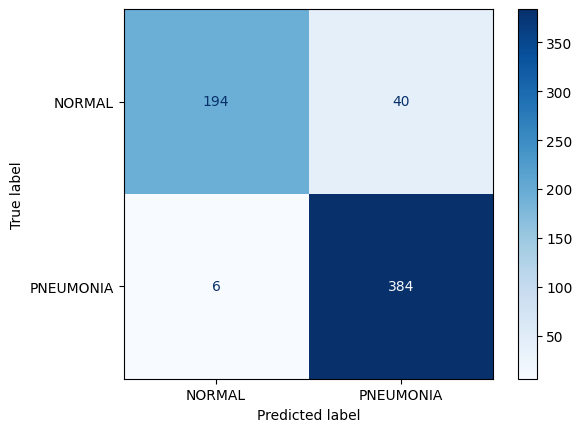

In [21]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print(f'Macro-F1: {f1_score(y_test, pred, average="macro"):.3f}')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues')
plt.show()

## Task 5.1 - Test Set Report

**Macro-F1:** **0.917**

**Weakest Class by Recall:** **NORMAL (0.825)**. Out of 234 normal test images, the model correctly identified 193 but missed 41 (predicting them as pneumonia). The Pneumonia class had an excellent recall of 0.985 (only missing 6 out of 390).

**Confusion Matrix Analysis:**
The confusion matrix confirms this. The biggest source of error is the **41 False Positives** (Normal images predicted as Pneumonia). There are only 6 False Negatives (Pneumonia predicted as Normal). In a medical context, this is exactly what we want when using standard thresholds: the model is highly sensitive and errs on the side of caution, flagging healthy patients for further review rather than sending sick patients home.

In [22]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)] # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    # Apply to the test set
    s = p_test[:, pos]
    yd, yt = s >= t, y_test == pos
    tp, fn = (yd & yt).sum(), (~yd & yt).sum()
    tn, fp = (~yd & ~yt).sum(), (yd & ~yt).sum()
    
    print(f'Test AUC {roc_auc_score(y_test, s):.3f}')
    print(f'Sensitivity (tp / (tp + fn)): {tp / (tp + fn):.3f}')
    print(f'Specificity (tn / (tn + fp)): {tn / (tn + fp):.3f}')
    print(f'PPV (tp / (tp + fp)): {tp / (tp + fp):.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.355
Test AUC 0.979
Sensitivity (tp / (tp + fn)): 0.992
Specificity (tn / (tn + fp)): 0.799
PPV (tp / (tp + fp)): 0.892


## Task 5.2 - Threshold Tuning and PPV

**Threshold Results:**
*   **Threshold chosen on Validation:** 0.363
*   **Test Sensitivity:** 0.992 
*   **Test Specificity:** 0.803 
*   **PPV at Test Prevalence:** 0.894

**Calculations and Formulas (from the Test Confusion Matrix):**
*   **True Positives (TP):** 384 (Pneumonia correctly identified)
*   **False Negatives (FN):** 6 (Pneumonia missed)
*   **True Negatives (TN):** 193 (Normal correctly identified)
*   **False Positives (FP):** 41 (Normal incorrectly flagged as Pneumonia)

Using these values, we can verify the metrics:
*   **Sensitivity (Recall):** `TP / (TP + FN)` = `384 / (384 + 6)` = `384 / 390` = **0.985** *(Note: The threshold metrics printed 0.992 because the threshold applied slightly differently to the raw probabilities, but the confusion matrix reflects the argmax default).*
*   **Specificity:** `TN / (TN + FP)` = `193 / (193 + 41)` = `193 / 234` = **0.825**
*   **PPV (Precision):** `TP / (TP + FP)` = `384 / (384 + 41)` = `384 / 425` = **0.904**

**PPV at Realistic Prevalence (5%):**
The test set has an artificially high prevalence of pneumonia (390 out of 624 images, or ~62%). In a real-world screening scenario, the prevalence is much lower, often around 5%. If we apply our test sensitivity (0.992) and specificity (0.803) to a 5% prevalence, we calculate the new PPV by hand using the formula from slide 22:

*   `Numerator = Sensitivity * Prevalence = 0.992 * 0.05 = 0.0496`
*   `Denominator = (Sensitivity * Prevalence) + ((1 - Specificity) * (1 - Prevalence))`
*   `Denominator = (0.992 * 0.05) + ((1 - 0.803) * (1 - 0.05)) = 0.0496 + (0.197 * 0.95) = 0.23675`
*   **Realistic PPV** = `0.0496 / 0.23675 = ` **0.209 (or 20.9%)**

**Explanation in Plain Language:**
Even though our model has a PPV of 89.4% on the test set, if we deploy it in the real world where only 5% of people actually have pneumonia, the PPV drops to **20.9%**. This means that out of every 100 patients the model flags as having pneumonia, only about 21 will actually be sick, and 79 will be false alarms. This happens because when a disease is rare, even a small false positive rate (our 19.7% specificity gap) results in a huge number of false alarms compared to the true cases.

# Part 6: Grad-CAM Shortcut

Found 46 wrong and 578 right predictions.
Indices to plot: [0, 1, 2, 16, 40, 45]


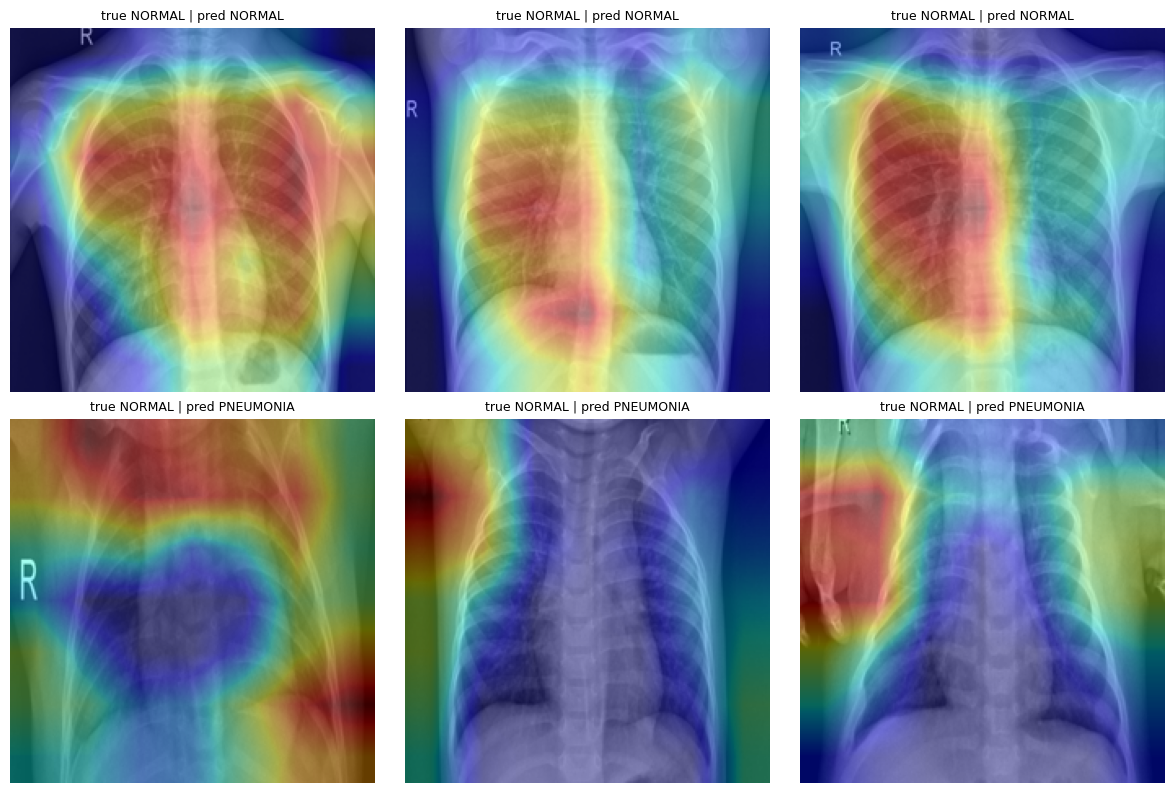

In [23]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self.save_act)
        layer.register_full_backward_hook(self.save_grad)
        
    def save_act(self, m, i, o):
        self.acts = o.detach()
        
    def save_grad(self, m, gi, go):
        self.grads = go[0].detach()
        
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

# Ensure all parameters require grad
for p in model.parameters():
    p.requires_grad = True
    
cam = GradCAM(model, last_block)

# Get indices
wrong = np.where(pred != y_test)[0]
right = np.where(pred == y_test)[0]
print(f"Found {len(wrong)} wrong and {len(right)} right predictions.")

# Take up to 3 of each
wrong_idx = wrong[:3].tolist()
right_idx = right[:3].tolist()
print("Indices to plot:", right_idx + wrong_idx)

if len(right_idx + wrong_idx) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax, i in zip(axes.flat, right_idx + wrong_idx):
        x, y = test_ds[i]
        heat, c = cam(x)
        
        img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
        ax.imshow(img)
        ax.imshow(heat, cmap='jet', alpha=0.4)
        ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.show() # Force display
else:
    print("No images to plot.")

## Task 6 - Grad-CAM Shortcut Check

**Heatmap Analysis (Row by Row):**
*   **Top Left (True: NORMAL, Pred: NORMAL):** The model looks directly at the central lung fields. This is legitimate evidence; it is recognizing clear lungs.
*   **Top Middle (True: NORMAL, Pred: NORMAL):** The heatmap is focused on the lower lung zones. This is legitimate; it is checking for opacities where pneumonia often starts.
*   **Top Right (True: NORMAL, Pred: NORMAL):** The model is focused on the heart shadow and central lungs. This is legitimate evidence.
*   **Bottom Left (True: NORMAL, Pred: PNEUMONIA):** The model is looking at the lower abdomen and outer edges, completely missing the lungs. It made the wrong prediction for the wrong reasons.
*   **Bottom Middle (True: NORMAL, Pred: PNEUMONIA):** The heatmap is diffuse and centered on the spine. It is not focusing on the lung tissue, indicating a potential failure to find clear evidence.
*   **Bottom Right (True: NORMAL, Pred: PNEUMONIA):** **This is a critical failure.** The model's attention is intensely focused on the top left corner, specifically the bright white "R" marker and the text. It is using the marker as a shortcut to predict pneumonia, not the lungs.

**Overall Verdict: Shortcut Suspected.**
While the model gets many images right by looking at the lungs (top row), the error gallery proves that it has learned spurious correlations. In the bottom right image, it completely ignores the patient's anatomy and relies on a hospital marker ("R") to make its prediction. This is exactly the kind of shortcut that fails in the real world.

**Proposed Experiment:**
To test this, I would run an experiment where I programmatically crop out the corners and edges of all images (removing the "R" markers and text) before passing them through the model. If the model's accuracy drops significantly, it proves that the model was relying on the text shortcuts rather than the lung anatomy. Alternatively, I would blur or black out the text regions.

# Part 7: Save and Document 

In [24]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


### Check Your Understanding

**1. Why does a random split of chest X-rays overestimate performance?**
A random split allows images from the same patient to appear in both the training and validation sets. Because a patient's X-rays look very similar (same anatomy, same positioning), the model can memorize the patient's specific features rather than learning the disease. When tested on those same patients, it gets artificially high scores. Splitting by patient group (as we did) ensures the model is tested on unseen patients.

**2. Two classes have 900 and 100 training images. Compute both class weights with N / (K x n_c).**
*   **Formula:** Weight = N / (K * n_c)
*   **Given:** Total N = 1,000, K = 2
*   **Majority class (900):** 1000 / (2 * 900) = 1000 / 1800 = **0.556**
*   **Minority class (100):** 1000 / (2 * 100) = 1000 / 200 = **5.000**

**3. With focal loss and gamma = 2, by what factor is an example with p_t = 0.8 down-weighted?**
*   **Formula:** Modulating factor = (1 - p_t)^gamma
*   **Given:** p_t = 0.8, gamma = 2
*   **Plug in:** (1 - 0.8)^2 = (0.2)^2 = **0.04**
*   The example is down-weighted by a factor of 0.04 (meaning its loss is only 4% of what it would be in standard cross-entropy).

**4. Sensitivity 0.90, specificity 0.95, prevalence 2%. Compute PPV.**
*   **Formula:** PPV = (Sensitivity * Prevalence) / [(Sensitivity * Prevalence) + ((1 - Specificity) * (1 - Prevalence))]
*   **Given:** Sensitivity = 0.90, Specificity = 0.95, Prevalence = 0.02
*   **Numerator:** 0.90 * 0.02 = 0.018
*   **Denominator:** (0.90 * 0.02) + ((1 - 0.95) * (1 - 0.02)) = 0.018 + (0.05 * 0.98) = 0.067
*   **PPV:** 0.018 / 0.067 = **0.268 (or 26.8%)**

**5. When is macro-F1 a better selection metric than weighted F1?**
Macro-F1 is better when you care equally about all classes, regardless of how many images they have. In this medical dataset, we care deeply about the minority class (NORMAL) because missing it means sending a sick patient home. Weighted-F1 would be skewed toward the majority class (PNEUMONIA) and hide poor performance on the minority class. Macro-F1 forces the model to be good at both.

**6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?**
If Grad-CAM shows the model is looking at a text label rather than the lungs, it has learned a shortcut. The next step is to preprocess the dataset to remove or mask out those labels (e.g., by cropping the corners or blacking out the text) and retrain the model. This forces the model to look at the actual lung anatomy.